# EDA: BubblSpace relational passages (Qwen3-30B), v3 vs v4 generator

**Dataset:** [`TheFireHacker/bubblspace-relational-passages-Qwen3-30B`](https://huggingface.co/datasets/TheFireHacker/bubblspace-relational-passages-Qwen3-30B), 222,088 kept passages (CC BY-SA 4.0).

Each passage was written by Qwen3-30B-A3B from a real Wikipedia paragraph, to teach one *semantic relation* (cause–effect, part–whole, comparison …). A second Qwen3 pass acted as a fact-check **judge**: `PASS` → `train` split, `FAIL` → `rejected` config with the judge's critique.

The data came from two versions of the generator, told apart by the **`relation_source`** column:

| `relation_source` | generator | how the relation was picked |
|---|---|---|
| `requested` | v3 (first ~67k rows) | We **assigned** one relation; the model had to use it even if the article didn't support it. The first EDA showed this produced contrived comparison/spatial passages. |
| `chosen_from_3` | v4 (remaining ~155k rows) | The model saw **3 candidate relations** and chose the one that fits the article (`relation_candidates` holds all 3). The judge also fails contrived relations, and stock openings ("People often mix up…") are banned. |

**Question this notebook answers:** did v4 fix the forced-relation problem? The go/no-go number is the **blind contrived rate** in section 5.

Sections: 1 setup · 2 overview (all rows) · 3 quality checks · 4 **v3 vs v4 comparison** · 5 **blind labelling** · 6 summary.

## 1. Setup

### 1.1 Install libraries and log in to Hugging Face
- `datasets` downloads the parquet shards from the Hub; `pandas` / `matplotlib` / `seaborn` are for tables and charts.
- The dataset is public, so login isn't strictly needed, but a token raises the download rate limit. Store it in Colab under **🔑 Secrets → `HF_TOKEN`** (enable notebook access).
- A warning about `bottleneck` after the install is harmless.

In [2]:
!pip -q install -U datasets huggingface_hub pyarrow pandas matplotlib seaborn

from google.colab import userdata
from huggingface_hub import login

login(token=userdata.get("HF_TOKEN"))   # reads the token from Colab Secrets
print("logged in")

logged in


### 1.2 Load kept + rejected passages
- `train` split = passages the judge **passed** (what goes into training).
- `rejected` config = passages the judge **failed**, with a `critique` column explaining why.
- Both are converted to pandas DataFrames: `df` (kept) and `dfr` (rejected).
- **`relation_source` safety fill:** the earliest v3 shards were written before this column existed. The published parquet already fills it, but if any row is missing it we mark it `requested` (that's what those rows were).
- Expect roughly **222k kept** and a larger rejected set; download is a few hundred MB (≈1–2 min).

In [3]:
from datasets import load_dataset
import pandas as pd

REPO = "TheFireHacker/bubblspace-relational-passages-Qwen3-30B"

kept = load_dataset(REPO, split="train")
rej = load_dataset(REPO, "rejected", split="train")

df = kept.to_pandas()     # judge PASS
dfr = rej.to_pandas()     # judge FAIL (+ critique)

# make sure every row says which generator produced it
for d in (df, dfr):
    if "relation_source" not in d.columns:
        d["relation_source"] = "requested"
    d["relation_source"] = d["relation_source"].fillna("requested")

print("kept:", len(df), "rejected:", len(dfr))
print("overall pass rate: {:.1%}".format(len(df) / (len(df) + len(dfr))))
print("\nkept by generator:\n", df["relation_source"].value_counts())
print("\nrejected by generator:\n", dfr["relation_source"].value_counts())
print("\nkept columns:", list(df.columns))
print("rejected columns:", list(dfr.columns))
df.head(3)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


README.md:   0%|          | 0.00/9.24k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/25 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/25 [00:00<?, ?it/s]

data/train-00011.parquet: reconstructing file:   0%|          |  0.00B / 4.94MB            

data/train-00006.parquet: reconstructing file:   0%|          |  0.00B / 6.00MB            

... (100 outputs left out)

rejected/rejected-00024.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

kept: 222088 rejected: 262246
overall pass rate: 45.9%

kept by generator:
 relation_source
chosen_from_3    155221
requested         66867
Name: count, dtype: int64

rejected by generator:
 relation_source
chosen_from_3    190353
requested         71893
Name: count, dtype: int64

kept columns: ['text', 'mode', 'relation', 'format', 'level', 'topic', 'source_title', 'source_url', 'idx', 'relation_source', 'relation_candidates']
rejected columns: ['text', 'critique', 'mode', 'relation', 'format', 'source_title', 'idx', 'relation_source']


,text,mode,relation,format,level,topic,source_title,source_url,idx,relation_source,relation_candidates
0,People sometimes mix up what a public official...,grounded,input_output,confusion,a general adult reader,NaN,John Rose (Minnesota politician),https://en.wikipedia.org/wiki/John%20Rose%20%2...,0,requested,None
1,People often confuse the drachma with the obol...,grounded,contrast_concession,confusion,a general adult reader,NaN,Ancient drachma,https://en.wikipedia.org/wiki/Ancient%20drachma,4,requested,None
2,People sometimes mix up how N-World and Mirai ...,grounded,spatial,confusion,a general adult reader,NaN,N-World,https://en.wikipedia.org/wiki/N-World,5,requested,None


## 2. Overview (all rows, both generators)

### 2.1 Passage length
- Counts words (whitespace-separated) and characters for every passage.
- The generator dropped anything under 80 words, so `kept under 80 words` should be **0**.
- `approx kept tokens` uses ≈1.3 tokens per English word; the real tokenizer count for the training pool was **65.06M tokens**.

In [4]:
import re

def word_count(t):
    return len(re.findall(r"\S+", t or ""))

for d in (df, dfr):
    d["n_words"] = d["text"].map(word_count)
    d["n_chars"] = d["text"].map(lambda t: len(t or ""))

print("KEPT words:\n", df["n_words"].describe())
print("\nREJECTED words:\n", dfr["n_words"].describe())
print("\nkept under 80 words:", int((df["n_words"] < 80).sum()))
print("approx kept tokens (words*1.3): {:,}".format(int(df["n_words"].sum() * 1.3)))

KEPT words:
 count    222088.000000
mean        230.244709
std          54.031071
min          93.000000
25%         186.000000
50%         227.000000
75%         271.000000
max         449.000000
Name: n_words, dtype: float64

REJECTED words:
 count    262246.000000
mean        231.859060
std          55.125926
min          99.000000
25%         182.000000
50%         234.000000
75%         274.000000
max         613.000000
Name: n_words, dtype: float64

kept under 80 words: 0
approx kept tokens (words*1.3): 66,474,963


### 2.2 Kept vs rejected (bar chart)
A quick picture of how many passages survived the fact-check judge overall.

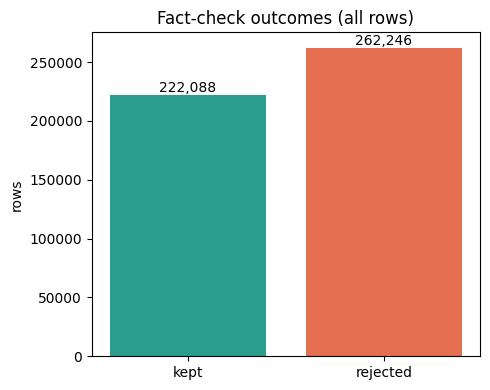

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["kept", "rejected"], [len(df), len(dfr)], color=["#2a9d8f", "#e76f51"])
ax.set_title("Fact-check outcomes (all rows)")
ax.set_ylabel("rows")
for i, v in enumerate([len(df), len(dfr)]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

### 2.3 Length distributions
If kept and rejected look the same, the judge isn't simply rejecting long or short passages; it's judging content.

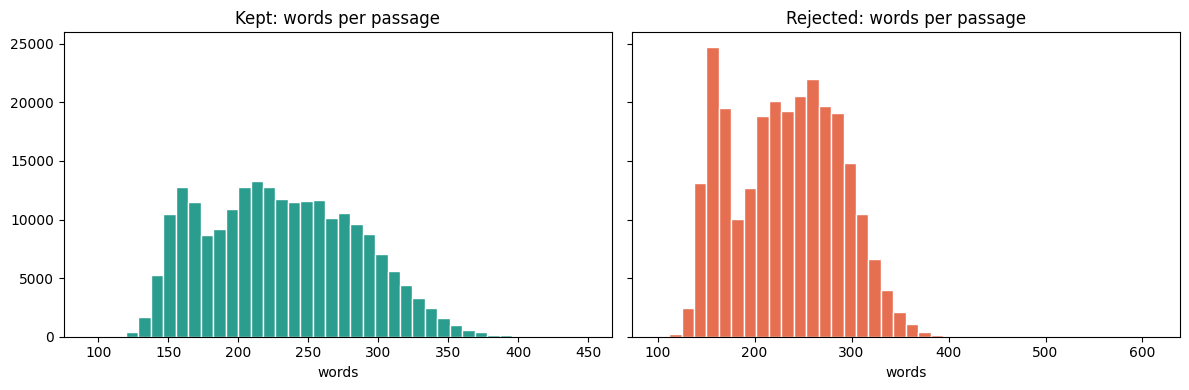

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].hist(df["n_words"], bins=40, color="#2a9d8f", edgecolor="white")
axes[0].set_title("Kept: words per passage"); axes[0].set_xlabel("words")
axes[1].hist(dfr["n_words"], bins=40, color="#e76f51", edgecolor="white")
axes[1].set_title("Rejected: words per passage"); axes[1].set_xlabel("words")
plt.tight_layout(); plt.show()

### 2.4 Pass rate by relation (both generators mixed)
- `pass_rate = kept / (kept + rejected)` for each of the 16 relations.
- In the first EDA (v3 only), **comparison** and **spatial** were lowest; the judge kept catching invented comparisons. Section 4.1 splits this by generator.

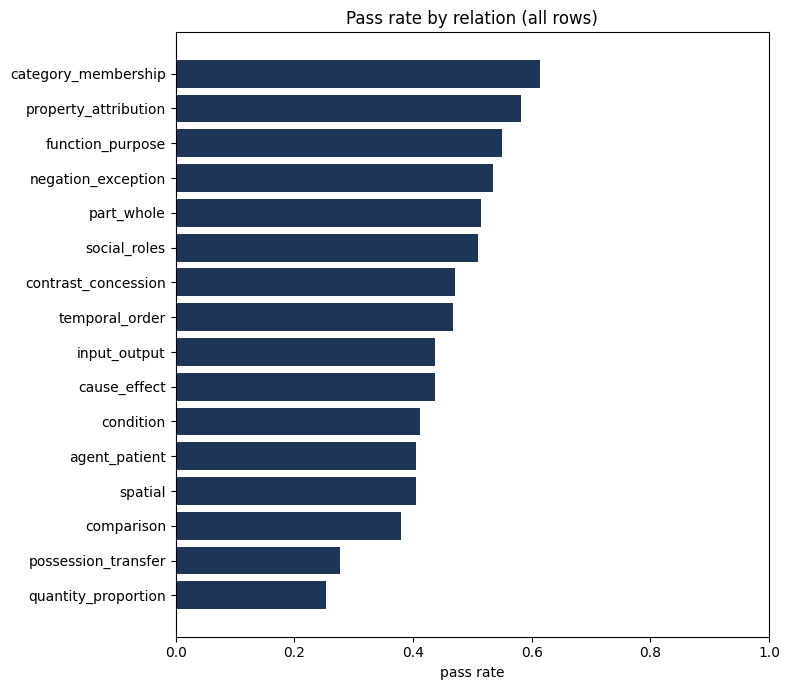

,kept,rejected,pass_rate
relation,,,
category_membership,23742,14904,0.614346
property_attribution,22468,16118,0.582284
function_purpose,16543,13546,0.549802
negation_exception,6355,5525,0.534933
part_whole,20948,19697,0.515389
social_roles,14192,13661,0.509532
contrast_concession,16692,18749,0.470980
temporal_order,14368,16314,0.468288
input_output,9130,11750,0.437261


In [7]:
kr = df["relation"].value_counts()
rr = dfr["relation"].value_counts()
pass_rel = pd.DataFrame({"kept": kr, "rejected": rr}).fillna(0)
pass_rel["pass_rate"] = pass_rel["kept"] / (pass_rel["kept"] + pass_rel["rejected"])
pass_rel = pass_rel.sort_values("pass_rate")

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(pass_rel.index, pass_rel["pass_rate"], color="#1d3557")
ax.set_xlim(0, 1); ax.set_xlabel("pass rate"); ax.set_title("Pass rate by relation (all rows)")
plt.tight_layout(); plt.show()
pass_rel.sort_values("pass_rate", ascending=False)

### 2.5 Read one passage
Change `i` to any row number to read a full passage with its format, relation, generator and source article.

In [8]:
from IPython.display import display, Markdown

i = 0  # change me
row = df.iloc[i]
display(Markdown(
    f"**row {i} | {row['format']} | {row['relation']} | {row['relation_source']} | {row['source_title']}**\n\n"
    + row["text"]
))

**row 0 | confusion | input_output | requested | John Rose (Minnesota politician)**

People sometimes mix up what a public official does with what results from their work. Specifically, they may confuse the effort a politician puts in—like working with others across party lines—with the actual outcome, such as new laws or community projects. In reality, the process (the effort) is about collaboration and negotiation. For example, the source says John Rose worked across the aisle to get votes for legislation. This means his daily actions involved listening, compromising, and building support—these are the inputs. The outputs, or results, are the laws passed or projects funded that help people in his district.

Another common mix-up is confusing the role of a teacher with the value of a sports facility named after them. Rose was a physical education teacher, so his job was to teach students how to stay active and healthy. That’s an input: his time, energy, and instruction in the classroom. But the output is something different—the Guidant John Rose Minnesota Oval, a sports facility named in his honor. This oval wasn’t created by his teaching, but by his later political work and support for youth sports. The facility is a lasting result of his advocacy, not a direct product of his classroom teaching.

The confusion happens because both teaching and public service involve helping youth and supporting communities. But one is a daily job (input), while the other is a long-term benefit (output), and the two aren’t the same thing, even when linked by a person’s values and dedication.

### 2.6 The `topic` column
`topic` is only filled for *ungrounded* passages (written from a topic name with no Wikipedia text). Every passage here is grounded, so `topic` is always empty, which is expected. **Pending decision:** drop the column or replace it with a domain label (like section 3.4's).

In [9]:
blank = df["topic"].isna() | (df["topic"].astype(str).str.strip().isin(["", "None"]))
print("kept rows:", len(df))
print("topic blank/missing:", int(blank.sum()), "({:.1%})".format(blank.mean()))
print(df["topic"].value_counts(dropna=False).head(5))

kept rows: 222088
topic blank/missing: 222088 (100.0%)
topic
NaN    222088
Name: count, dtype: int64


### 2.7 Reading level and length by format
- `level` = the reader the passage was written for (e.g. "a general adult reader").
- The boxplot shows whether some formats (qa, explainer, …) run longer than others.

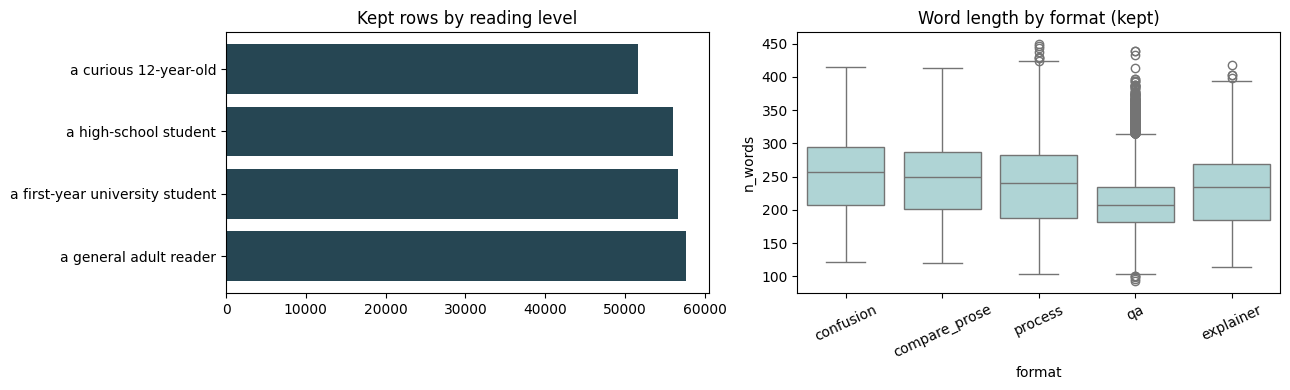

In [10]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
lvl = df["level"].value_counts()
axes[0].barh(lvl.index, lvl.values, color="#264653")
axes[0].set_title("Kept rows by reading level")
sns.boxplot(data=df, x="format", y="n_words", ax=axes[1], color="#a8dadc")
axes[1].set_title("Word length by format (kept)")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

## 3. Quality checks

### 3.1 Source diversity
Each Wikipedia article should be used only once or twice. If one article produced many passages, the model would over-learn it. `max repeats` should stay small (1–3).

unique Wikipedia titles in kept: 212,308 / 222,088 rows
max repeats of one title: 4


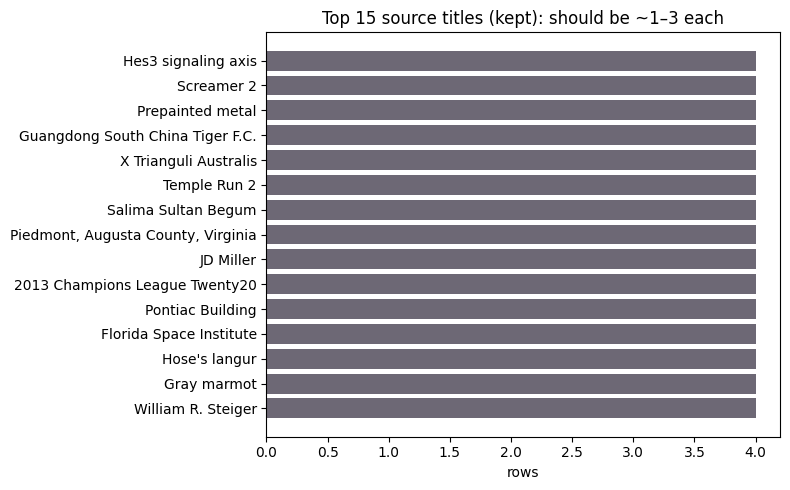

In [11]:
n_unique = df["source_title"].nunique()
top = df["source_title"].value_counts().head(15)
print(f"unique Wikipedia titles in kept: {n_unique:,} / {len(df):,} rows")
print("max repeats of one title:", int(df["source_title"].value_counts().max()))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index[::-1], top.values[::-1], color="#6d6875")
ax.set_title("Top 15 source titles (kept): should be ~1–3 each"); ax.set_xlabel("rows")
plt.tight_layout(); plt.show()

### 3.2 Pass rate by format, and relation × format heatmaps
- **Format** = the writing style asked for: `explainer`, `confusion` (clearing up a mix-up), `qa`, `process`, `compare_prose`.
- The first heatmap shows the **pass rate** for each relation × format cell (red = judge rejects most). The second shows **how many** kept passages each cell has, so we can spot thin cells.

,kept,rejected,pass_rate
format,,,
qa,68944,22043,0.757735
process,42892,56394,0.432005
confusion,38830,56711,0.406422
explainer,39780,59133,0.402172
compare_prose,31642,67965,0.317668


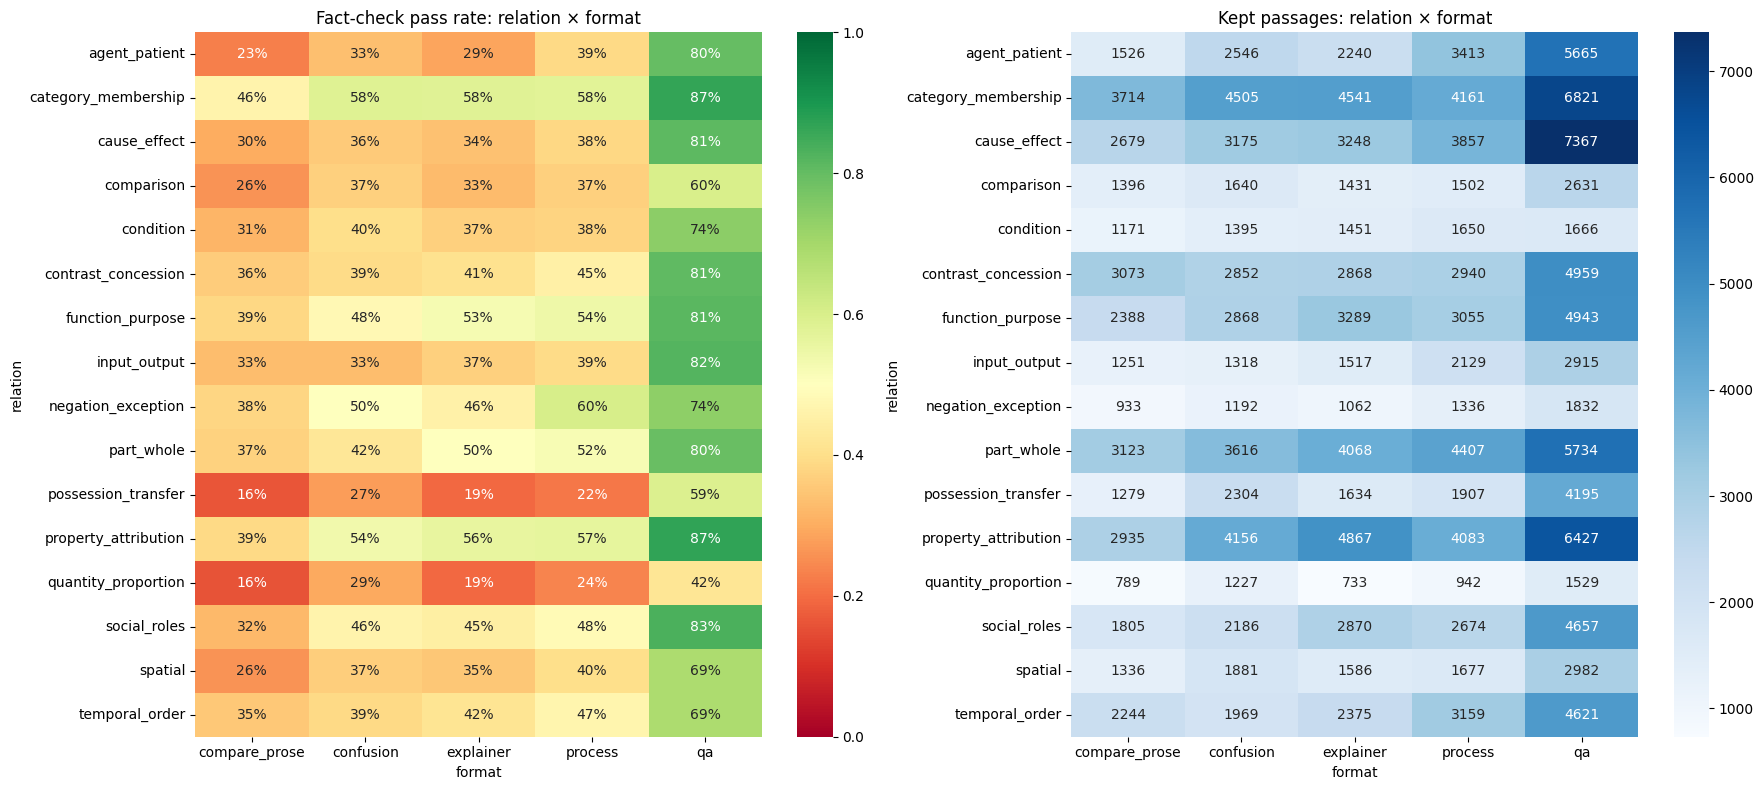

In [12]:
kf, rf = df["format"].value_counts(), dfr["format"].value_counts()
pass_fmt = pd.DataFrame({"kept": kf, "rejected": rf}).fillna(0)
pass_fmt["pass_rate"] = pass_fmt["kept"] / (pass_fmt["kept"] + pass_fmt["rejected"])
display(pass_fmt.sort_values("pass_rate", ascending=False))

k = df.groupby(["relation", "format"]).size()
r = dfr.groupby(["relation", "format"]).size()
both = pd.DataFrame({"kept": k, "rej": r}).fillna(0)
both["pass_rate"] = both["kept"] / (both["kept"] + both["rej"])

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
sns.heatmap(both["pass_rate"].unstack("format"), annot=True, fmt=".0%", cmap="RdYlGn",
            vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("Fact-check pass rate: relation × format")
sns.heatmap(both["kept"].unstack("format").fillna(0).astype(int), annot=True, fmt="d",
            cmap="Blues", ax=axes[1])
axes[1].set_title("Kept passages: relation × format")
plt.tight_layout(); plt.show()

### 3.3 Why the judge rejected passages (critique themes)
- Searches each rejection critique for keyword patterns (rough regex labels, not exact).
- One critique can match several themes, so shares add up to more than 100%.
- v4's judge also checks **"contrived relation"**, so that theme should appear mostly in `chosen_from_3` rejects. The second table splits themes by generator.

In [13]:
themes = {
    "unsupported / not in source": r"not (?:supported|mentioned|stated)|no (?:evidence|mention)|unsupported",
    "fabricated / invented":       r"fabricat|invent|introduces?",
    "contradicts source":          r"contradict",
    "wrong entity / misattribution": r"misattribut|incorrectly (?:attribut|assign|implies)|wrong (?:person|entity)",
    "timeline / order":            r"timeline|chronolog|before|after|preced",
    "numbers":                     r"\bnumber|figure|percent|\d{4}",
    "logic / illogical":           r"illogical|logical|inconsistent|nonsens",
    "contrived / forced relation": r"contriv|forced|artificial|not a natural|doesn't fit|does not fit",
}
crit = dfr["critique"].fillna("").str.lower()
for name, pat in themes.items():
    dfr[name] = crit.str.contains(pat, regex=True)

print(dfr[list(themes)].mean().sort_values(ascending=False).round(3).to_string())
print("\nTheme share by generator:")
display(dfr.groupby("relation_source")[list(themes)].mean().round(2).T)

wrong entity / misattribution    0.479
unsupported / not in source      0.399
numbers                          0.297
timeline / order                 0.251
fabricated / invented            0.125
contradicts source               0.101
logic / illogical                0.050
contrived / forced relation      0.045

Theme share by generator:


relation_source,chosen_from_3,requested
unsupported / not in source,0.41,0.38
fabricated / invented,0.14,0.09
contradicts source,0.09,0.14
wrong entity / misattribution,0.48,0.48
timeline / order,0.23,0.29
numbers,0.28,0.35
logic / illogical,0.05,0.05
contrived / forced relation,0.06,0.01


### 3.4 Rough domain label
- Guesses each passage's subject area (person, place, biology, …) from keywords. It's crude: about a third will be `other`.
- The heatmap shows whether some relations fail more in some domains (e.g. comparison on sports articles).
- This could also become the replacement for the empty `topic` column.
- Takes ≈1 min on 222k rows.

domain
other       0.413
place       0.135
person      0.130
media       0.113
sports      0.077
business    0.051
biology     0.045
history     0.037
Name: proportion, dtype: float64


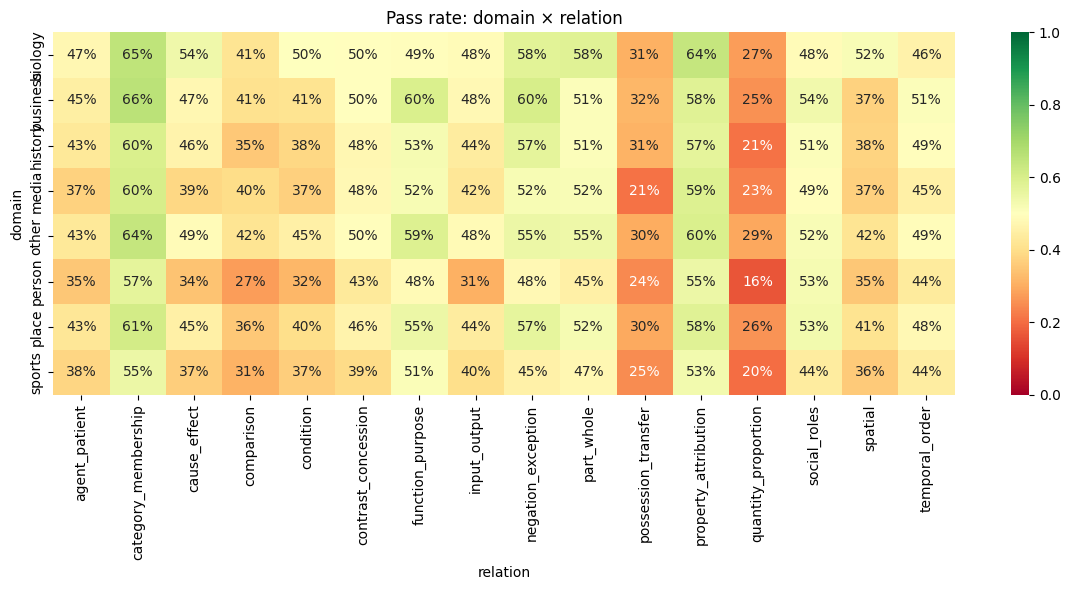

In [14]:
def guess_domain(text):
    t = text.lower()
    if re.search(r"\b(?:born|died|his career|her career|was elected|served as|played for)\b", t): return "person"
    if re.search(r"\b(?:village|town|city|district|county|province|river|located in)\b", t): return "place"
    if re.search(r"\b(?:species|genus|plant|animal|bird|fish|insect|habitat)\b", t): return "biology"
    if re.search(r"\b(?:album|song|film|novel|band|episode|series)\b", t): return "media"
    if re.search(r"\b(?:war|battle|empire|dynasty|treaty|revolution)\b", t): return "history"
    if re.search(r"\b(?:team|season|league|match|championship|tournament)\b", t): return "sports"
    if re.search(r"\b(?:company|business|market|founded|brand)\b", t): return "business"
    return "other"

df["domain"] = df["text"].map(guess_domain)
dfr["domain"] = dfr["text"].map(guess_domain)
print(df["domain"].value_counts(normalize=True).round(3))

kd = df.groupby(["domain", "relation"]).size()
rd = dfr.groupby(["domain", "relation"]).size()
dom = pd.DataFrame({"kept": kd, "rej": rd}).fillna(0)
dom["pass_rate"] = dom["kept"] / (dom["kept"] + dom["rej"])
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(dom["pass_rate"].unstack("relation"), annot=True, fmt=".0%", cmap="RdYlGn",
            vmin=0, vmax=1, ax=ax)
ax.set_title("Pass rate: domain × relation")
plt.tight_layout(); plt.show()

### 3.5 Browse one format × relation cell
Set `FORMAT`, `RELATION` and `N` to read random kept passages from one cell. Add `GEN` to restrict to one generator (`"requested"` or `"chosen_from_3"`, or `None` for both).

In [15]:
FORMAT, RELATION, N, GEN = "confusion", "input_output", 5, None   # edit me
sub = df[(df["format"] == FORMAT) & (df["relation"] == RELATION)]
if GEN:
    sub = sub[sub["relation_source"] == GEN]
print(f"{len(sub)} kept passages for {FORMAT} × {RELATION} ({GEN or 'both generators'})")
for _, row in sub.sample(min(N, len(sub)), random_state=0).iterrows():
    display(Markdown(f"---\n**{row['source_title']}** · {row['relation_source']} · {row['level']}\n\n{row['text']}"))

1318 kept passages for confusion × input_output (both generators)


---
**Pamela Abshire** · chosen_from_3 · a high-school student

Some might confuse the purpose of a biosensor with the function of a control system, thinking they both do the same thing. But they are different in what they take in and what they produce. A biosensor takes in biological signals—like the presence of a certain molecule or cell activity—and turns them into electrical signals that can be measured. This is its input (biological data) and output (electrical data). The source says Abshire works on CMOS biosensors for cell-based sensing, which means these devices detect living cell behavior and convert it into a readable signal. On the other hand, a control system takes in data—like the output from a sensor—and uses it to make decisions, such as adjusting a device’s behavior. The source mentions closed loop control of MEMS and microfluidic systems, which means the system receives information (input) and then acts on it (output), like turning something on or off based on the data. The mix-up happens because both involve signals and systems that react to data, but the key difference is where the process starts. Biosensors begin with a biological signal and turn it into data. Control systems begin with data and produce a physical response. The input to a biosensor is life-related, while the output is measurable electrical information. The input to a control system is data from a sensor (including biosensors), and the output is an action or change. So the direction of the relationship matters: biosensors transform biology into data, while control systems use data to create physical changes. Understanding this helps clarify how tiny sensors can be part of bigger systems that respond to the body or environment.

---
**Constitution of Rwanda** · requested · a curious 12-year-old

People often mix up what a system *takes in* versus what it *produces*. Let’s clear up two common mix-ups using the Rwandan constitution.

First, some think that having women in government is the *input*—like a rule that says “we must include women.” But actually, the *input* is the *rule itself*—the law saying political groups can’t divide people by things like gender or tribe. The *output* is the result: more women getting seats in parliament. The constitution doesn’t just ask for women to be there—it creates conditions so that women can win seats, and that’s what happens: nearly half the lower house is female, and extra seats are set aside just for women. So the rule (input) leads to more women in power (output).

Second, some think that the number of women in parliament is the *input*—like a number you start with. But no. The *input* is the law requiring fair representation. The *output* is the actual number of women in office. The constitution says nothing about how many women *must* be there—only that no group can be excluded, and that extra seats are reserved for women. So the law (input) leads to more women being elected (output). The mix-up happens because people see the final result—many women in government—and think that’s what the system started with. But it didn’t. The system started with a rule that treats everyone fairly, and that rule *produced* the result of more women in power. The order is: rule → result, not result → rule.

---
**Dega Deva Kumar Reddy** · chosen_from_3 · a curious 12-year-old

Some people might think that producing a film is the main goal of someone who runs a school, but that’s not true. The real input for Srujana School was a group of people who believed in a different way of learning—like Deva Kumar, Manchireddy Sivaram, and Eleanor Watts. Their input was a shared vision: to help underprivileged children grow through freedom, self-discovery, and nature-based learning. The output was a school that wasn’t like regular schools—it had no walls, no strict rules, and no exams. Instead, it had trees, open spaces, and learning that came from experience. The school’s output was not just education, but also books like A School Under Trees and A Journey With Children, which shared how children learned by exploring their own thoughts and feelings.

On the other hand, producing films like Ammayi Bagundi or Essence of Life was something Deva Kumar did outside the school, using his own skills and ideas. That was a separate output from his work in education. The confusion happens because both the school and the films are linked to Deva Kumar, and both involve creativity. But the key difference is: the school’s main input was a belief in alternative education, and its output was children growing in confidence and independence. The films, while creative, were not the result of the school’s process—they were side projects. So the real input-output story belongs to the school: people with a vision created a new kind of learning place.

---
**Christine Lafuente** · requested · a general adult reader

People often mix up what goes into a painting process versus what comes out of it—specifically, the materials used versus the visual effect they create. A common confusion is thinking that the soft, blurred edges in Christine Lafuente’s paintings are the result of using a certain kind of paint, like a special kind of watercolor or blur tool. But the source says her work features "a blurriness of edges" not because of a specific material, but because of how she applies paint: she works *alla prima*, meaning in one sitting, using a wet-into-wet technique. So the soft edges are not an input (like a type of paint or tool) but an output—a visual result of the process.

The real input is the act of painting quickly and directly, with wet paint applied while the previous layer is still damp. This method allows colors to blend naturally and forms to merge, which leads to the soft, flowing look. The blurriness is not something she adds on purpose like a filter; it emerges from the physical behavior of the paint as it’s applied. That’s why the process (wet-on-wet, fast, continuous) produces the effect (fuzzy edges, dissolved forms).

Another source of confusion might be thinking that her focus on cityscapes and seascapes is the result of a planned subject selection. But the passage shows she is a plein air painter—meaning she paints outdoors—so her subject is shaped by where she chooses to stand and look. The location (city or sea) is an input: where she sets up her easel. But the output is the way light and color interact with those scenes, captured in loose, energetic strokes. People might assume the subject drives the style, but it's actually the method—painting quickly, on-site, with wet paint—that shapes the final look.

So, the key is: the *process* (wet-on-wet, fast, outdoor) leads to the *effect* (soft edges, fluid forms). Mixing up input and output leads to misunderstanding how the paintings are made.

---
**BlackBerry Pearl** · chosen_from_3 · a first-year university student

The Pearl 81xx series phones use a specific chip that connects peripherals directly, which affects how data moves into and out of the device. The chip enables fast transfers between components like the USB port and the microSDHC card. This means that when you send data to the phone—such as copying a file from a computer via USB—the data enters the phone quickly, and when you take data out—like transferring a large file from the phone’s storage to a computer—it also moves rapidly. The source says that a 1 GB file can be transferred in less than 70 seconds, which shows how fast the output side of the process is, and how fast the input side is too. The key point is that the chip is designed so that both incoming and outgoing data benefit from high speed, not just one direction.

A common confusion is thinking that fast file transfer only means the phone can send data quickly to a computer. Some might assume that fast transfer only applies when saving files to the phone from a computer. But the source clearly says the chip allows “fast connection to the microSDHC card” and “ultra-fast transfers” in both directions—meaning the speed works both ways. The mix-up happens because people often focus on uploading (sending files to the phone) as the main use case, but the chip’s design supports equal speed in both directions. The source doesn’t say the phone is faster at sending than receiving, or vice versa—it highlights the overall performance of the data movement system. So, the real input-output relationship is balanced: what goes in comes out fast, and what comes out can be sent in fast too. This dual-direction speed is what the chip enables. The input is data arriving from the computer or card, and the output is data leaving to the computer or card—both are fast because the chip connects peripherals directly.

## 4. v3 (`requested`) vs v4 (`chosen_from_3`)

### 4.1 Pass rate and stock openings by generator
- **Pass rate:** v4 may pass *fewer* passages than v3 because its judge is stricter (it also fails contrived relations). Lower here can be a good sign.
- **Stock openings:** the first EDA found ≈15% of passages starting with templates like "People often mix up…" / "What happens if…". v4 banned them in the prompt and filtered them out, so `chosen_from_3` should be **≈0%**.
- The last part lists each generator's most common 4-word openings so you can see the variety directly.

In [16]:
src = pd.DataFrame({
    "kept": df["relation_source"].value_counts(),
    "rejected": dfr["relation_source"].value_counts(),
})
src["pass_rate"] = (src["kept"] / (src["kept"] + src["rejected"])).round(3)
print(src, "\n")

STOCK = r"^(?:people often|people sometimes|a common confusion|one common confusion|what happens if)"
df["stock_open"] = df["text"].str.lower().str.strip().str.contains(STOCK, regex=True)
print("stock-opening share by generator:")
print(df.groupby("relation_source")["stock_open"].mean().round(3))

for s, g in df.groupby("relation_source"):
    print(f"\n--- top 4-word openings: {s} ---")
    print(g["text"].str.split().str[:4].str.join(" ").value_counts().head(8).to_string())

                   kept  rejected  pass_rate
relation_source                             
chosen_from_3    155221    190353      0.449
requested         66867     71893      0.482 

stock-opening share by generator:
relation_source
chosen_from_3    0.00
requested        0.23
Name: stock_open, dtype: float64

--- top 4-word openings: chosen_from_3 ---
text
What is the main             2656
Some people might confuse    2043
What happened to the         1705
Who was responsible for      1347
Some people might mix        1198
The sequence of events       1153
What happened first: the      923
What is the relationship      858

--- top 4-word openings: requested ---
text
What happens if a            2702
People often mix up          2235
People sometimes mix up      1601
A common confusion is        1199
A common confusion arises    1134
What happens if the           578
People often confuse the      531
A common confusion people     496


### 4.2 Relation mix: assigned vs model-chosen
- For each generator: what share of kept passages uses each relation.
- **v3** was assigned relations from a fixed rotation, so its mix is roughly flat (minus judge rejections).
- **v4** picked what fits the article, so the mix should follow Wikipedia's content: more `category_membership`, `part_whole`, `property_attribution`; less `comparison` and `spatial`.
- `change` = v4 share − v3 share. Big negatives are relations v3 was over-forcing.

relation_source,chosen_from_3,requested,change
relation,,,
negation_exception,0.009,0.073,-0.064
input_output,0.030,0.068,-0.038
condition,0.023,0.056,-0.033
spatial,0.040,0.048,-0.008
possession_transfer,0.049,0.055,-0.006
quantity_proportion,0.022,0.027,-0.005
agent_patient,0.069,0.071,-0.002
temporal_order,0.065,0.064,0.001
comparison,0.040,0.036,0.004


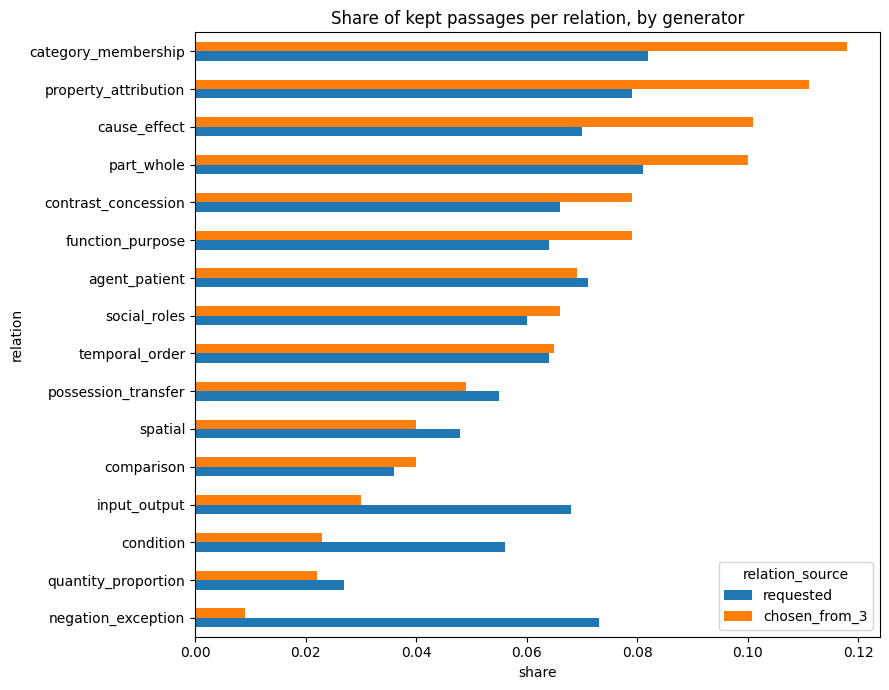

In [17]:
mix = pd.crosstab(df["relation"], df["relation_source"], normalize="columns").round(3)
mix["change"] = mix["chosen_from_3"] - mix["requested"]
display(mix.sort_values("change"))

fig, ax = plt.subplots(figsize=(9, 7))
mix[["requested", "chosen_from_3"]].sort_values("chosen_from_3").plot.barh(ax=ax)
ax.set_title("Share of kept passages per relation, by generator"); ax.set_xlabel("share")
plt.tight_layout(); plt.show()

### 4.3 Pick rate: when a relation was offered, how often did v4 choose it?
- Every v4 passage was offered 3 candidate relations (`relation_candidates`) and the model chose one (`relation`).
- `pick_rate = times chosen / times offered`. Choosing at random would give ≈0.33.
- **Below 0.33** = the model tends to *decline* that relation (good for comparison/spatial: it's refusing weak fits). **Above 0.33** = it prefers it when available.
- Note this counts only kept passages; the pick may also be affected by which ones the judge passed.
- `to_list` handles candidates stored as a real list or as a string like `"['a','b','c']"`.

In [18]:
import ast
import numpy as np

v4 = df[df["relation_source"] == "chosen_from_3"].copy()

def to_list(x):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return []
    if isinstance(x, str):
        try:
            return list(ast.literal_eval(x))
        except Exception:
            return [x]
    return list(x)

v4["cands"] = v4["relation_candidates"].map(to_list)
print("v4 rows with 3 candidates:", int((v4["cands"].map(len) == 3).sum()), "of", len(v4))

offered = v4.explode("cands")["cands"].value_counts()
chosen = v4["relation"].value_counts()
pick = pd.DataFrame({"offered": offered, "chosen": chosen}).fillna(0).astype(int)
pick["pick_rate"] = (pick["chosen"] / pick["offered"]).round(3)
display(pick.sort_values("pick_rate"))
print("(random choice ≈ 0.33)")

v4 rows with 3 candidates: 155221 of 155221


,offered,chosen,pick_rate
negation_exception,29942,1469,0.049
quantity_proportion,27698,3408,0.123
condition,27069,3600,0.133
input_output,27457,4607,0.168
comparison,28843,6167,0.214
spatial,28940,6237,0.216
possession_transfer,24130,7627,0.316
social_roles,30447,10203,0.335
temporal_order,29273,10080,0.344
agent_patient,26958,10668,0.396


(random choice ≈ 0.33)


### 4.4 Side by side: the relations that failed in the first EDA
- For each weak relation (comparison, spatial, possession_transfer, and quantity if present), shows **one v3 passage and one v4 passage**.
- Read them in pairs: v3 should read forced ("X is larger than Y" with no basis), v4 should only use the relation when the article supports it.
- Change `random_state` to see a different pair.

In [19]:
weak = [r for r in df["relation"].unique()
        if any(k in r for k in ("compar", "quant", "spatial", "possession"))]
print("relations checked:", weak)
for r in weak:
    for s in ["requested", "chosen_from_3"]:
        sub = df[(df["relation"] == r) & (df["relation_source"] == s)]
        if len(sub) == 0:
            continue
        row = sub.sample(1, random_state=3).iloc[0]
        display(Markdown(f"---\n**{r} · {s}** ({len(sub):,} rows) · {row['source_title']}\n\n{row['text'][:900]}"))

relations checked: ['spatial', 'comparison', 'quantity_proportion', 'possession_transfer']


---
**spatial · requested** (3,225 rows) · Lincoln Mayorga

Lincoln Mayorga’s career unfolded across multiple layers of the music world, each role positioned in relation to the others like instruments in a layered arrangement. The former, his work as a session musician, sat behind the scenes of countless recordings, contributing subtly but indispensably to the sound of major artists. The latter, his role as a staff pianist for a major film studio, placed him more visibly within a structured environment, where his presence was both expected and integral. Though the former was often anonymous, the latter gave him a consistent platform, allowing his artistry to be heard in the visual storytelling of movies.

Between these two roles stood his collaborations with singers and performers, where he moved from one project to the next, much like a musician shifting between stages. His work with Phil Ochs, for instance, was not merely technical but deeply p

---
**spatial · chosen_from_3** (6,237 rows) · List of newspapers in Italy

Many people confuse the physical availability of newspapers with their actual circulation reach. Some assume that because a newspaper is sold in Rome and a few other places, it must be widely read across the country. However, the source clarifies that certain opinion or political newspapers are available only in Rome and a few other locations, meaning their physical presence is limited to specific areas. This local availability does not imply broad readership. In contrast, regional or local newspapers, though not distributed nationwide, may have larger circulation than many countrywide papers. The key distinction lies in where the paper is physically accessible versus how many people actually read it. A newspaper’s presence in a city like Rome doesn’t guarantee it is read by people outside that region. The spatial condition—being sold in certain cities—does not determine its reach. Inste

---
**comparison · requested** (2,433 rows) · Ken Potts

People sometimes confuse the USS Arizona with Ford Island, thinking one is larger than the other. In reality, Ford Island is much larger than the USS Arizona. The Arizona was a battleship, a large warship designed for heavy combat, but it was still a single vessel floating in the water. Ford Island, on the other hand, is a real island—land surrounded by water—located in Pearl Harbor. It’s a physical piece of land that can hold buildings, roads, and people. Because the Arizona was stationed near Ford Island and was attacked while moored there, some assume the island might be the same size or even bigger. But the island is clearly the larger entity, both in physical size and in how it supports human activity. The confusion arises because the two are often mentioned together in historical accounts—especially when describing events like the attack on December 7, 1941, where survivors were br

---
**comparison · chosen_from_3** (6,167 rows) · 2000 Grand Prix motorcycle racing season

Who performed better in the 2000 Grand Prix season, Kenny Roberts Jr. or Valentino Rossi?  
Kenny Roberts Jr. performed better because he won the championship, while Rossi finished second as a rookie.

What happened when comparing the number of race wins between Garry McCoy and Valentino Rossi?  
Garry McCoy had more wins because he achieved three victories, while Rossi won two races.

Why was Valentino Rossi's rookie season considered impressive despite early crashes?  
It was impressive because he still earned second place in the standings, with multiple podium finishes, even after setbacks.

What occurred when comparing the number of podiums between Rossi and McCoy?  
Rossi had more podiums because he reached the top three eight times, while McCoy’s three wins do not indicate the same number of podium finishes.

Why did Kenny Roberts Jr. finish ahead of Rossi in the championship?  
He

---
**quantity_proportion · requested** (1,812 rows) · Saúl Ubaldini

After democracy returned, a man became the head of a large workers' union. From this position, he led 13 major strikes against the government in power at the time. The number of strikes he led was more than double the number of strikes typically associated with a single union leader in a short period. Once a different political party came into power, the union’s aggressive actions decreased significantly. This shift happened because the new leaders were part of the same political movement the union had supported before. Later, this same man was removed from his leadership role by people who supported the new president. The number of supporters who replaced him was greater than the number who remained loyal to him, showing a clear change in power. Even though he had publicly supported the new president’s campaign, he disagreed with the new economic policies. He refused to leave the union’

---
**quantity_proportion · chosen_from_3** (3,408 rows) · Pressure-retarded osmosis

The amount of energy produced by a pressure-retarded osmosis (PRO) system is directly tied to the size of the membrane used, but not in a one-to-one way. Specifically, using a membrane that is only half as large as the one needed for maximum output still allows the system to generate nearly all of its potential energy—about 95% of the theoretical power. This shows that the relationship between membrane size and energy output is not linear; reducing the membrane area significantly still results in a very high proportion of the total possible output. The key factor enabling this efficiency is the difference in salt concentration between the two streams involved. When a low-salt stream, such as treated wastewater, mixes with a high-salt stream, like seawater or desalination brine, the osmotic pressure drives water through the membrane. The resulting flow of water into the concentrated side 

---
**possession_transfer · requested** (3,692 rows) · War of Internet Addiction

The video *War of Internet Addiction* was created by mainland Chinese players who felt their experiences and emotions were ignored by the outside world. These players were restricted to playing on servers located only in mainland China, which limited their access to a global gaming community. This restriction led to frustration, and the video became a way for them to express their grievances. The video was not made by a company or government, but by individuals using the game *World of Warcraft* as a setting. In this way, the players borrowed the game’s virtual world to tell their real-life stories. They used the game engine to create a kind of story film, which allowed them to present their feelings in a creative and powerful way.

The video also criticized various groups and their actions. The Chinese government, for example, was seen as imposing rules that affected the players. It pro

---
**possession_transfer · chosen_from_3** (7,627 rows) · Sentimiento (album)

Ivy Queen received a gold and platinum certification for her album Sentimiento in the United States, which means the record label or organization officially gave her proof of selling over 100,000 copies. This recognition was presented to her by Don Francisco during a show called Don Francisco Presenta. At the same event, other artists like Jenni Rivera and Gloria Trevi also received certifications for their albums, showing that multiple musicians were honored with the same kind of award at once. The certification was not just a token—it was a formal acknowledgment of sales success, and Ivy Queen was the recipient of this official recognition for her work. The act of giving and receiving the certification is a clear example of possession transfer: someone handed over the certificate, and Ivy Queen took it as proof of her achievement. This moment marked a personal milestone for her, especi

## 5. Blind labelling (the go/no-go check)

- Takes **30 random kept passages from each generator** (60 total), shuffles them, and shows them **without saying which generator wrote each one**, so your judgement isn't biased.
- For each, type `n` (natural: the relation fits the article), `c` (contrived: the relation feels forced or invented), `s` skip, or `q` to stop early. Partial runs still count.
- At the end it reveals the contrived rate per generator.
- **Decision rule:** if `chosen_from_3` is clearly lower than `requested` (e.g. ≤ half), v4 fixed the problem and the data is good for 2.5a. If they're similar, tell Claude which relations/formats felt contrived (section 5.1 breaks it down).
- ≈15–20 min for 60 passages.

In [20]:
N = 30
pool = (pd.concat([g.sample(min(N, len(g)), random_state=7) for _, g in df.groupby("relation_source")])
          .sample(frac=1, random_state=7).reset_index(drop=True))

labels = []
for i, row in pool.iterrows():
    # relation_source is deliberately NOT shown
    display(Markdown(f"### {i+1}/{len(pool)} · `{row['format']}` × `{row['relation']}` · {row['source_title']}\n\n{row['text']}"))
    a = input("natural (n) / contrived (c) / skip (s) / quit (q): ").strip().lower()
    if a == "q":
        break
    if a in ("n", "c"):
        labels.append({"relation_source": row["relation_source"], "relation": row["relation"],
                       "format": row["format"], "domain": row["domain"], "label": a})

lab = pd.DataFrame(labels)
print(f"\nlabelled {len(lab)}")
print(lab.groupby("relation_source")["label"].apply(lambda s: f"{(s=='c').mean():.0%} contrived of {len(s)}"))

### 1/60 · `explainer` × `function_purpose` · Pleasant Valley, Missouri

In Pleasant Valley, the median age is 36 years, which means half the people are younger and half are older than that. This number helps us understand how young or old the population tends to be. A similar number, the median income for a household, is $48,684. This tells us how much money a typical family earns on average. While both numbers describe averages, they measure different things: age shows the spread of people by how old they are, and income shows how much money families make. Another number, the median income for a family, is higher at $54,891. This means families make more than households overall, possibly because families usually have more adults working. Also, the per capita income—how much money each person earns—was $26,084. This is different from household income because it’s divided among all people, not just those in a home. These numbers help us see how people in Pleasant Valley are doing in life, like whether they’re young, how much money they earn, and if they’re struggling financially.

natural (n) / contrived (c) / skip (s) / quit (q): n


### 2/60 · `compare_prose` × `part_whole` · Charles Nelson Tripp

The bitumen extracted from the land in Enniskillen Township formed the foundational raw material for a series of industrial processes that transformed it into finished products. This substance, obtained through boiling, was not merely a commodity but the essential component in a broader system of manufacturing. The former, the bitumen, was processed to yield oils, paints, burning fluids, varnishes, and other materials, each of which relied on its unique properties. These products, in turn, were the intended outputs of the company’s operations, fulfilling specific industrial and commercial functions. The land itself, comprising 1,450 acres acquired by Tripp, served as the source from which the entire enterprise drew its supply, making it the physical and economic base of the venture. The company’s charter explicitly defined its mission as the transformation of the bitumen into useful goods, indicating that the raw material was the starting point for a sequence of industrial activities. Without the bitumen, there could be no manufacturing; without the manufacturing, the company’s purpose would remain unfulfilled. The process of boiling the bitumen into usable substances was thus not incidental but central, forming the core of the enterprise’s function. The connection between the natural resource and the manufactured goods illustrates a clear part-whole relationship: the bitumen was a part of a larger system of production, and the various end products were the outcomes of that system. Each item produced was a distinct manifestation of the same raw input, shaped through industrial effort into materials with practical applications. The land, the bitumen, the manufacturing process, and the final products were interdependent, each fulfilling a role within the whole.

natural (n) / contrived (c) / skip (s) / quit (q): c


### 3/60 · `qa` × `comparison` · Paul Gertler

Which has more influence on global development policy: traditional methods of assessing programs or randomized evaluations?  
Randomized evaluations have more influence because they provide strong evidence on what works, which Gertler helped promote through his leadership in impact evaluation.

Who has more responsibility in advancing evidence-based policies: a single researcher or a network of organizations?  
A network of organizations has more responsibility because Gertler helped establish a culture of evaluation across institutions like the World Bank and 3ie.

Which has greater reach: a textbook that explains impact evaluation or a single government program?  
The textbook has greater reach because it is widely used to train people globally, while programs affect only specific populations.

What happens if a country uses only opinions instead of impact evaluations when designing social programs?  
The country is less likely to improve outcomes because impact evaluations help determine what actually works, a focus Gertler championed.

True or false: A single person can have more impact on global health than a large international initiative?  
False. A large initiative like 3ie has more impact because it supports many evaluations across multiple countries, unlike a single individual.

Which has more authority in shaping how development programs are tested: informal discussions or formal evaluation systems?  
Formal evaluation systems have more authority because Gertler helped build them into major institutions like the World Bank.

natural (n) / contrived (c) / skip (s) / quit (q): s


### 4/60 · `qa` × `category_membership` · Summer Reading Challenge

What kind of thing is the Summer Reading Challenge Sheet?  
It is a tool used to track reading progress, because the passage says it is where children record books they’ve read and collect stickers.

Who receives a medal and certificate in the challenge?  
Children who complete the challenge receive these items, because the passage states this happens after they read six books and collect all stickers.

Why is the digital Book Sorter considered a child-friendly resource?  
It provides recommendations from other children, because the passage mentions it uses peer-to-peer recommendations added by kids who have read the books.

What type of online platform supports the Summer Reading Challenge?  
It is an interactive website, because the passage describes it as available year-round and allowing children to create profiles and chat about books.

What kind of feature helps children choose books on the website?  
It is the digital Book Sorter, because the passage identifies it as a tool that offers help on what to read next.

What is the main purpose of the stickers on the challenge sheet?  
They mark progress toward completing the challenge, because the passage says children get them after recording two books and showing their sheet to a librarian.

natural (n) / contrived (c) / skip (s) / quit (q): q

labelled 2
relation_source
chosen_from_3    100% contrived of 1
requested          0% contrived of 1
Name: label, dtype: str


### 5.1 Where the contrived ones are
Breaks your labels down by relation, format and domain within each generator, to show *which* relations or formats still feel forced in v4. Small counts, so treat as hints.

In [21]:
if len(lab):
    for col in ["relation", "format", "domain"]:
        print(f"\n--- contrived rate by {col} ---")
        print(lab.groupby(["relation_source", col])["label"]
                 .apply(lambda s: f"{(s=='c').mean():.0%} of {len(s)}").unstack(0).fillna("").to_string())
else:
    print("no labels yet: run the cell above")


--- contrived rate by relation ---
relation_source  chosen_from_3 requested
relation                                
function_purpose                 0% of 1
part_whole           100% of 1          

--- contrived rate by format ---
relation_source chosen_from_3 requested
format                                 
compare_prose       100% of 1          
explainer                       0% of 1

--- contrived rate by domain ---
relation_source chosen_from_3 requested
domain                                 
other                           0% of 1
person              100% of 1          


## 6. Summary table
One table with the headline numbers for each generator. Paste it back to Claude along with the section 5 result.

In [22]:
def summarize(s):
    k = df[df["relation_source"] == s]
    r = dfr[dfr["relation_source"] == s]
    out = {
        "kept_rows": len(k),
        "rejected_rows": len(r),
        "pass_rate": f"{len(k)/max(1, len(k)+len(r)):.1%}",
        "median_words": int(k["n_words"].median()) if len(k) else 0,
        "stock_opening_share": f"{k['stock_open'].mean():.1%}" if len(k) else "",
        "unique_sources": int(k["source_title"].nunique()),
        "relations_used": int(k["relation"].nunique()),
        "comparison_share": f"{(k['relation']=='comparison').mean():.1%}" if len(k) else "",
        "spatial_share": f"{(k['relation']=='spatial').mean():.1%}" if len(k) else "",
    }
    if "lab" in globals() and len(lab):
        l = lab[lab["relation_source"] == s]
        out["blind_contrived_rate"] = f"{(l['label']=='c').mean():.0%} of {len(l)}" if len(l) else ""
    return out

summary = pd.DataFrame({s: summarize(s) for s in ["requested", "chosen_from_3"]})
summary

,requested,chosen_from_3
kept_rows,66867,155221
rejected_rows,71893,190353
pass_rate,48.2%,44.9%
median_words,244,220
stock_opening_share,23.0%,0.0%
unique_sources,66099,150383
relations_used,16,16
comparison_share,3.6%,4.0%
spatial_share,4.8%,4.0%
blind_contrived_rate,0% of 1,100% of 1
